# 03. Кластеризация регионов: построение и сравнение разбиений

Пространство признаков — 4 стандартизованных показателя (z-оценки), см. ноутбук 02.
Пять методов, от «чисто признаковых» к «чисто территориальным»:

| № | Метод | Учёт пространства |
|---|---|---|
| 1 | k-средних (k-means) | нет — базовая типология |
| 2 | ClustGeo: Уорд на смешанной матрице различий | мягкий: параметр α задаёт вес географической близости |
| 3 | Уорд с ограничением смежности | жёсткий: объединяются только соседние кластеры |
| 4 | SKATER (разрезание минимального остовного дерева) | жёсткий: кластеры — связные подграфы |
| 5 | Max-p (максимум регионов при пороге численности населения) | жёсткий + число кластеров выводится из данных |

In [1]:
import sys, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import esda
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import shortest_path
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from spopt.region import MaxPHeuristic, Skater

from src.common import PROCESSED, RESULTS, MAPS, FEATURES, LABELS, SHORT, SEED, connected_queen, partition_metrics
from src.viz import cluster_map, short_name, CAT, SEQ, INK2, MUTED, BLUE, RED

pd.set_option("display.width", 220)
gdf = gpd.read_file(PROCESSED / "regions_digital_2021.gpkg")
w, _ = connected_queen(gdf)
w_r = connected_queen(gdf)[0]; w_r.transform = "r"
RAWX = gdf[FEATURES].to_numpy()
Z = StandardScaler().fit_transform(RAWX)
ZC = [f"z_{f}" for f in FEATURES]
gdf[ZC] = Z
pc = PCA(2).fit(Z); PC = pc.transform(Z)
print(gdf.shape, "| граф соседства связный:", w.n_components == 1)

E:\da-practice\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(85, 13) | граф соседства связный: True


## 1. Выбор числа кластеров
Для k = 2…8 сравниваются инерция (сумма квадратов внутри кластеров, «локоть»), силуэт
$s=\frac{1}{n}\sum_i\frac{b_i-a_i}{\max(a_i,b_i)}$ (выше — лучше), индекс Калински–Харабаша
$CH=\frac{SS_B/(k-1)}{SS_W/(n-k)}$ (выше — лучше) и Дэвиса–Болдина (ниже — лучше) для k-средних и для
иерархического метода Уорда без ограничений.

In [2]:
rows = []
for k in range(2, 9):
    for name, lab in [("k-средних", KMeans(k, n_init=200, random_state=SEED).fit_predict(Z)),
                      ("Уорд", AgglomerativeClustering(k, linkage="ward").fit_predict(Z))]:
        m = partition_metrics(Z, lab, w)
        rows.append({"метод": name, "k": k, "R2": m["R2"], "силуэт": m["silhouette"], "CH": m["CH"], "DB": m["DB"],
                     "мин. размер": m["min_size"]})
ksel = pd.DataFrame(rows)
ksel.to_csv(RESULTS / "03_k_selection.csv", index=False, encoding="utf-8")
ksel.pivot(index="k", columns="метод", values=["R2", "силуэт", "CH", "DB"]).round(3)

R2           силуэт               CH                DB       
метод k-средних   Уорд k-средних   Уорд k-средних    Уорд k-средних   Уорд
k                                                                         
2         0.546  0.513     0.468  0.429    99.986  87.606     0.817  0.871
3         0.657  0.635     0.399  0.395    78.499  71.284     0.904  0.854
4         0.736  0.704     0.317  0.283    75.414  64.240     1.028  0.984
5         0.783  0.772     0.322  0.300    72.332  67.688     1.031  1.029
6         0.810  0.802     0.291  0.292    67.206  63.850     1.038  1.042
7         0.830  0.823     0.287  0.274    63.434  60.514     1.049  1.017
8         0.848  0.842     0.312  0.284    61.407  58.534     0.887  1.010

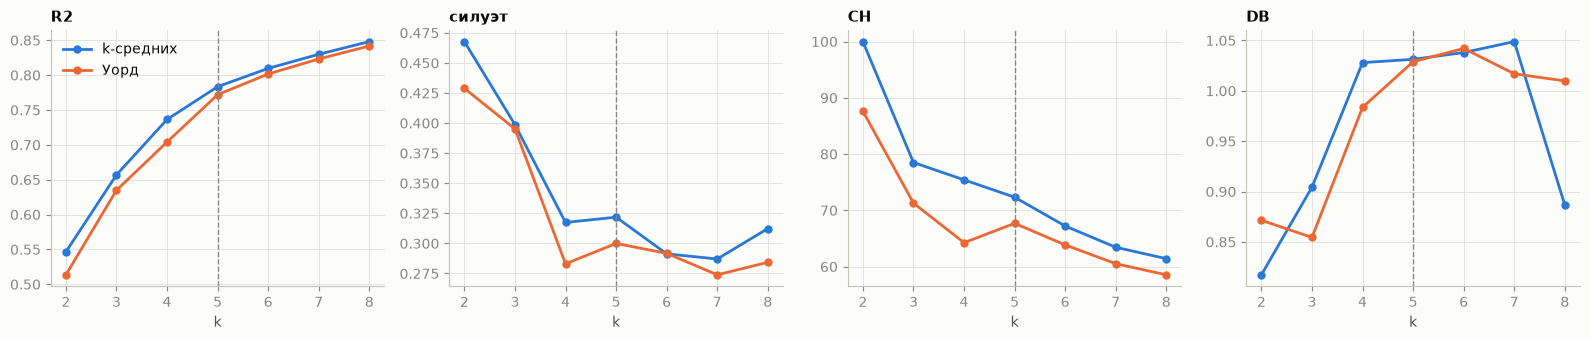

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, metric in zip(ax, ["R2", "силуэт", "CH", "DB"]):
    for (name, d), c in zip(ksel.groupby("метод", sort=False), CAT):
        a.plot(d.k, d[metric], marker="o", ms=5, color=c, label=name)
    a.axvline(5, color=MUTED, ls="--", lw=1); a.set_title(metric, loc="left"); a.set_xlabel("k")
ax[0].legend()
plt.tight_layout(); plt.savefig(MAPS / "03_k_selection.png", dpi=150, bbox_inches="tight"); plt.show()

**Выбор k = 5.** Максимум силуэта при k = 2 соответствует тривиальному делению «выше/ниже среднего».
Среди k ≥ 3 силуэт k-средних максимален при k = 5, здесь же «локоть» кривой $R^2$ (прирост от 4 к 5
кластерам ≈ 5 п. п., дальше ≈ 3 п. п. и меньше), а наименьший кластер ещё содержит не менее 6–7 регионов.
Пять групп содержательно различимы (см. профили ниже). Для сравнимости все методы с заданным числом
кластеров строятся при k = 5.

In [4]:
K = 5

def order_labels(lab):
    """Перенумеровать кластеры 1..k по возрастанию среднего PC1 (общего уровня цифровизации)."""
    lab = np.asarray(lab)
    means = {c: PC[lab == c, 0].mean() for c in np.unique(lab)}
    rank = {c: i + 1 for i, c in enumerate(sorted(means, key=means.get))}
    return np.array([rank[c] for c in lab])

labels, timing = {}, {}

## 2. Методы
### 2.1. k-средних
$\min_{C_1..C_k}\sum_{c}\sum_{i\in C_c}\lVert z_i-\mu_c\rVert^2$; алгоритм Ллойда, 200 случайных стартов
(k-means++), лучший по инерции. Пространство не учитывается — это базовая признаковая типология.

In [5]:
t = time.time()
labels["k-средних"] = order_labels(KMeans(K, n_init=200, random_state=SEED).fit_predict(Z))
timing["k-средних"] = time.time() - t

### 2.2. ClustGeo — Уорд на смешанной матрице различий (Chavent и др., 2018)
Две матрицы различий, нормированные на максимум: $D_0$ — евклидовы расстояния в пространстве признаков,
$D_1$ — географические различия (длина кратчайшего пути в графе соседства, то есть «через сколько границ»).
Иерархическая кластеризация Уорда выполняется на

$$D_\alpha=\sqrt{(1-\alpha)D_0^2+\alpha D_1^2},\qquad \alpha\in[0,1].$$

При $\alpha=0$ это обычный Уорд, при $\alpha\to1$ — чисто географическое районирование. Связность кластеров
не гарантируется, но поощряется. Параметр $\alpha$ выбирается по критерию авторов метода: строятся доли
объяснённой неоднородности $Q_0(\alpha)$ по признакам и $Q_1(\alpha)$ по географии, нормированные на их
значения при $\alpha=0$ и $\alpha=1$; берётся $\alpha$, при котором потеря признаковой однородности
сравнивается с выигрышем пространственной.

In [6]:
D0 = squareform(pdist(Z)); D0 /= D0.max()
D1 = shortest_path(w.sparse, unweighted=True); D1 /= D1.max()

def ward_q(D, lab):
    """Доля объяснённой «инерции» для матрицы различий (псевдо-R²): 1 − W/T, W и T — по формуле Уорда."""
    D2 = D ** 2
    T = D2.sum() / (2 * len(lab))
    W = sum(D2[np.ix_(lab == c, lab == c)].sum() / (2 * (lab == c).sum()) for c in np.unique(lab))
    return 1 - W / T

def clustgeo(alpha, k=K):
    Da = np.sqrt((1 - alpha) * D0 ** 2 + alpha * D1 ** 2)
    return fcluster(linkage(squareform(Da, checks=False), "ward"), k, "maxclust")

alphas = np.round(np.arange(0, 1.0001, 0.05), 2)
q = pd.DataFrame([{"alpha": a, "Q0": ward_q(D0, l), "Q1": ward_q(D1, l)} for a in alphas for l in [clustgeo(a)]])
q["Q0n"] = q.Q0 / q.Q0.iloc[0]
q["Q1n"] = q.Q1 / q.Q1.iloc[-1]
alpha_star = float(q.loc[(q.Q0n - q.Q1n).abs().idxmin(), "alpha"])
q.to_csv(RESULTS / "03_clustgeo_alpha.csv", index=False, encoding="utf-8")
print("выбранное α =", alpha_star)
q.round(3).T

выбранное α = 0.25


,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
alpha,0.000,0.050,0.100,0.150,0.200,0.250,0.300,0.350,0.400,0.450,...,0.550,0.600,0.650,0.700,0.750,0.800,0.850,0.900,0.950,1.000
Q0,0.772,0.777,0.779,0.708,0.697,0.616,0.569,0.569,0.560,0.586,...,0.552,0.488,0.289,0.309,0.289,0.289,0.160,0.160,0.123,0.121
Q1,0.097,0.150,0.138,0.402,0.424,0.616,0.692,0.694,0.697,0.666,...,0.707,0.723,0.793,0.786,0.793,0.793,0.810,0.810,0.812,0.803
Q0n,1.000,1.006,1.009,0.918,0.904,0.798,0.738,0.737,0.726,0.759,...,0.715,0.632,0.374,0.400,0.374,0.374,0.207,0.207,0.159,0.156
Q1n,0.120,0.187,0.172,0.500,0.528,0.768,0.862,0.864,0.868,0.830,...,0.880,0.901,0.988,0.979,0.988,0.988,1.009,1.009,1.012,1.000


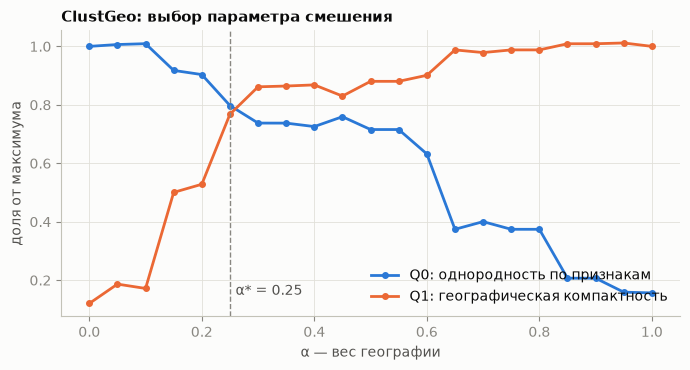

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(q.alpha, q.Q0n, marker="o", ms=4, color=CAT[0], label="Q0: однородность по признакам")
ax.plot(q.alpha, q.Q1n, marker="o", ms=4, color=CAT[1], label="Q1: географическая компактность")
ax.axvline(alpha_star, color=MUTED, ls="--", lw=1); ax.text(alpha_star + 0.01, 0.15, f"α* = {alpha_star}", color=INK2)
ax.set_xlabel("α — вес географии"); ax.set_ylabel("доля от максимума"); ax.legend(loc="lower right")
ax.set_title("ClustGeo: выбор параметра смешения", loc="left")
plt.tight_layout(); plt.savefig(MAPS / "03_clustgeo_alpha.png", dpi=150, bbox_inches="tight"); plt.show()

t = time.time()
labels[f"ClustGeo α={alpha_star}"] = order_labels(clustgeo(alpha_star))
timing[f"ClustGeo α={alpha_star}"] = time.time() - t
CG = f"ClustGeo α={alpha_star}"

### 2.3. Уорд с ограничением смежности
Агломеративная процедура Уорда, в которой на каждом шаге можно объединять только кластеры, соседние в
графе $W$ (`AgglomerativeClustering(connectivity=W)`). Все кластеры связны по построению.

In [8]:
t = time.time()
labels["Уорд со смежностью"] = order_labels(
    AgglomerativeClustering(K, linkage="ward", connectivity=w.sparse).fit_predict(Z))
timing["Уорд со смежностью"] = time.time() - t

### 2.4. SKATER (Assunção и др., 2006)
Рёбрам графа соседства приписывается вес $\lVert z_i-z_j\rVert$, строится минимальное остовное дерево,
затем $k-1$ раз удаляется ребро, дающее наибольшее снижение суммы квадратов внутри получающихся частей.
Ограничение: в каждом кластере не менее 3 регионов (`floor=3`), чтобы исключить кластеры-одиночки.

In [9]:
t = time.time()
sk = Skater(gdf, w, ZC, n_clusters=K, floor=3); sk.solve()
labels["SKATER"] = order_labels(sk.labels_)
timing["SKATER"] = time.time() - t

### 2.5. Max-p (Duque и др., 2012; эвристика Wei и др., 2021)
Ищется **наибольшее** число связных кластеров $p$ при ограничении: суммарное население каждого кластера
не меньше порога $L$; затем при найденном $p$ локальным поиском минимизируется неоднородность.
Порог $L$ = 15 млн человек (≈ 10 % населения страны, порядок населения федерального округа): так кластер —
макрорегион, сопоставимый по масштабу с другими методами. Москва (12,6 млн) не может образовать кластер
в одиночку.

In [10]:
gdf["pop"] = gdf.pop_thousands
np.random.seed(SEED)
t = time.time()
mp = MaxPHeuristic(gdf, w, ZC, "pop", 15000, top_n=5, max_iterations_construction=99); mp.solve()
labels["Max-p"] = order_labels(mp.labels_)
timing["Max-p"] = time.time() - t
print({m: len(np.unique(l)) for m, l in labels.items()})

{'k-средних': 5, 'ClustGeo α=0.25': 5, 'Уорд со смежностью': 5, 'SKATER': 5, 'Max-p': 8}


## 3. Качество разбиений
**В пространстве признаков:** $R^2=1-SS_W/SS_T$ (доля объяснённой дисперсии), силуэт, CH, DB.
**В географическом пространстве:**
- *фрагменты* — суммарное число связных частей кластеров в графе соседства (минимум = k: каждый кластер — один массив);
- *доля связей внутри кластеров* — доля пар соседних регионов с одинаковой меткой (1 — полностью районированная карта);
- *путевой силуэт* (path silhouette, Wolf и др., 2021) — силуэт, в котором расстояние до своего кластера
  учитывает только достижимых соседей;
- *компактность* — средний изопериметрический индекс $IPQ=4\pi A/P^2$ объединённых кластеров (1 — круг).

In [11]:
mrows = []
for name, lab in labels.items():
    m = partition_metrics(Z, lab, w, gdf=gdf)
    m["путевой силуэт"] = float(np.mean(esda.path_silhouette(Z, lab, w)))
    m["время, с"] = timing[name]
    mrows.append({"метод": name, **m})
metrics = pd.DataFrame(mrows).set_index("метод")
metrics = metrics.rename(columns={"silhouette": "силуэт", "min_size": "мин. размер", "fragments": "фрагменты",
                                  "within_links": "связи внутри", "IPQ": "компактность"})
metrics.to_csv(RESULTS / "03_partition_metrics.csv", encoding="utf-8")
metrics.round(3)

,k,R2,силуэт,CH,DB,мин. размер,фрагменты,связи внутри,компактность,путевой силуэт,"время, с"
метод,,,,,,,,,,,
k-средних,5,0.783,0.322,72.332,1.031,7,36,0.307,0.023,-0.098,0.399
ClustGeo α=0.25,5,0.616,0.016,32.038,2.774,9,16,0.604,0.033,0.153,0.001
Уорд со смежностью,5,0.381,0.109,12.332,2.379,2,5,0.875,0.119,0.075,0.002
SKATER,5,0.322,-0.049,9.515,3.143,3,5,0.839,0.106,0.266,0.105
Max-p,8,0.385,-0.121,6.874,7.730,5,8,0.510,0.074,0.108,2.129


## 4. Устойчивость
Показатели — результаты **выборочного** обследования, их значения содержат ошибку выборки. Устойчивое
разбиение не должно заметно меняться от небольшого возмущения данных. Опыт: к исходным процентам
добавляется независимый шум $N(0,\sigma^2)$, $\sigma$ = 1 и 2 п. п. (порядок ошибки выборки регионального
обследования), признаки заново стандартизуются, метод перезапускается (для k-средних — с новым случайным
стартом); сходство с исходным разбиением — скорректированный индекс Рэнда (ARI: 1 — совпадение,
0 — уровень случайного совпадения). 30 повторов (для Max-p — 10: он заметно медленнее).

In [12]:
def run(method, Zp, gdfp, seed):
    if method == "k-средних":
        return KMeans(K, n_init=50, random_state=seed).fit_predict(Zp)
    if method == CG:
        d0 = squareform(pdist(Zp)); d0 /= d0.max()
        Da = np.sqrt((1 - alpha_star) * d0 ** 2 + alpha_star * D1 ** 2)
        return fcluster(linkage(squareform(Da, checks=False), "ward"), K, "maxclust")
    if method == "Уорд со смежностью":
        return AgglomerativeClustering(K, linkage="ward", connectivity=w.sparse).fit_predict(Zp)
    if method == "SKATER":
        m = Skater(gdfp, w, ZC, n_clusters=K, floor=3); m.solve(); return m.labels_
    if method == "Max-p":
        np.random.seed(seed); m = MaxPHeuristic(gdfp, w, ZC, "pop", 15000, top_n=5, max_iterations_construction=99)
        m.solve(); return m.labels_

rng = np.random.default_rng(SEED)
stab = []
for sigma in (1.0, 2.0):
    for r in range(30):
        Xp = RAWX + rng.normal(0, sigma, RAWX.shape)
        Zp = StandardScaler().fit_transform(Xp)
        gp = gdf.copy(); gp[ZC] = Zp
        for method in labels:
            if method == "Max-p" and r >= 10:
                continue
            stab.append({"σ, п. п.": sigma, "метод": method, "повтор": r,
                         "ARI": adjusted_rand_score(labels[method], run(method, Zp, gp, SEED + r + 1))})
stab = pd.DataFrame(stab)
stab.to_csv(RESULTS / "03_stability.csv", index=False, encoding="utf-8")
stab_tab = stab.groupby(["метод", "σ, п. п."]).ARI.agg(["mean", "std", "min"]).unstack().round(3)
stab_tab

mean           std           min       
σ, п. п.              1.0    2.0    1.0    2.0    1.0    2.0
метод                                                       
ClustGeo α=0.25     0.742  0.648  0.149  0.138  0.456  0.304
Max-p               0.551  0.540  0.064  0.059  0.427  0.451
SKATER              0.752  0.694  0.269  0.224  0.158  0.180
k-средних           0.858  0.669  0.093  0.089  0.586  0.419
Уорд со смежностью  0.762  0.667  0.311  0.307  0.061  0.048

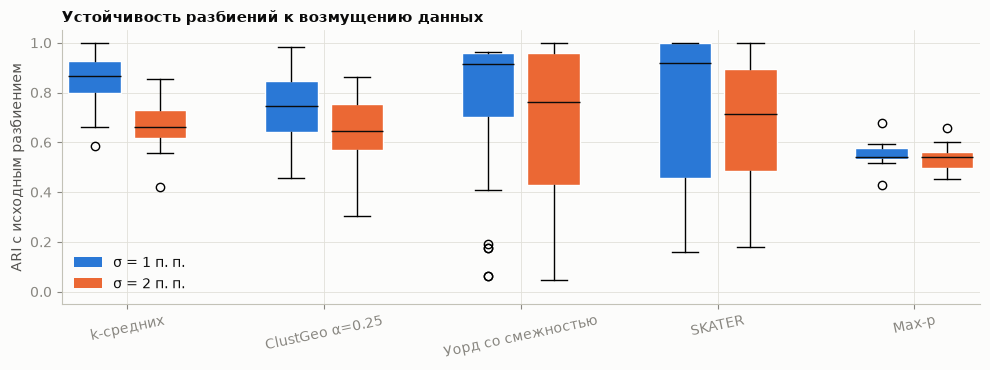

In [13]:
fig, ax = plt.subplots(figsize=(10, 3.8))
meths = list(labels)
for j, sigma in enumerate((1.0, 2.0)):
    d = [stab[(stab["метод"] == m) & (stab["σ, п. п."] == sigma)].ARI for m in meths]
    bp = ax.boxplot(d, positions=np.arange(len(meths)) * 3 + j, widths=0.8, patch_artist=True,
                    medianprops=dict(color="#0b0b0b"))
    for b in bp["boxes"]:
        b.set_facecolor(CAT[j]); b.set_edgecolor("#ffffff")
ax.set_xticks(np.arange(len(meths)) * 3 + 0.5, meths, rotation=12)
ax.set_ylabel("ARI с исходным разбиением"); ax.set_ylim(-0.05, 1.05)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=CAT[0], label="σ = 1 п. п."), Patch(facecolor=CAT[1], label="σ = 2 п. п.")], loc="lower left")
ax.set_title("Устойчивость разбиений к возмущению данных", loc="left")
plt.tight_layout(); plt.savefig(MAPS / "03_stability.png", dpi=150, bbox_inches="tight"); plt.show()

### Чувствительность к пространству признаков
Те же методы в пространстве двух первых главных компонент (94 % дисперсии): совпадает ли разбиение
с построенным по четырём z-оценкам.

In [14]:
gpc = gdf.copy(); gpc[ZC] = np.c_[PC, np.zeros((len(PC), 2))]   # 2 ГК + нулевые столбцы — те же расстояния
sens = {m: adjusted_rand_score(labels[m], run(m, np.c_[PC, np.zeros((len(PC), 2))], gpc, SEED)) for m in labels}
pd.Series(sens, name="ARI (4 z-оценки vs 2 ГК)").round(3)

k-средних             0.979
ClustGeo α=0.25       0.547
Уорд со смежностью    0.957
SKATER                0.416
Max-p                 0.615
Name: ARI (4 z-оценки vs 2 ГК), dtype: float64

## 5. Согласованность методов

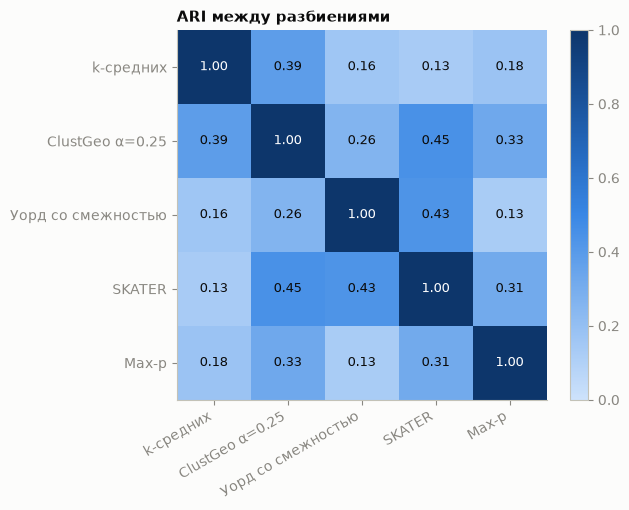

In [15]:
A = pd.DataFrame([[adjusted_rand_score(labels[a], labels[b]) for b in labels] for a in labels], index=labels, columns=labels)
A.to_csv(RESULTS / "03_ari_between_methods.csv", encoding="utf-8")
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(A, cmap=SEQ, vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(len(A)), A.columns, rotation=30, ha="right"); ax.set_yticks(range(len(A)), A.index)
for i in range(len(A)):
    for j in range(len(A)):
        ax.text(j, i, f"{A.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="#ffffff" if A.iloc[i, j] > 0.6 else "#0b0b0b")
plt.colorbar(im, ax=ax, fraction=0.046); ax.set_title("ARI между разбиениями", loc="left")
plt.tight_layout(); plt.savefig(MAPS / "03_ari_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Карты всех разбиений

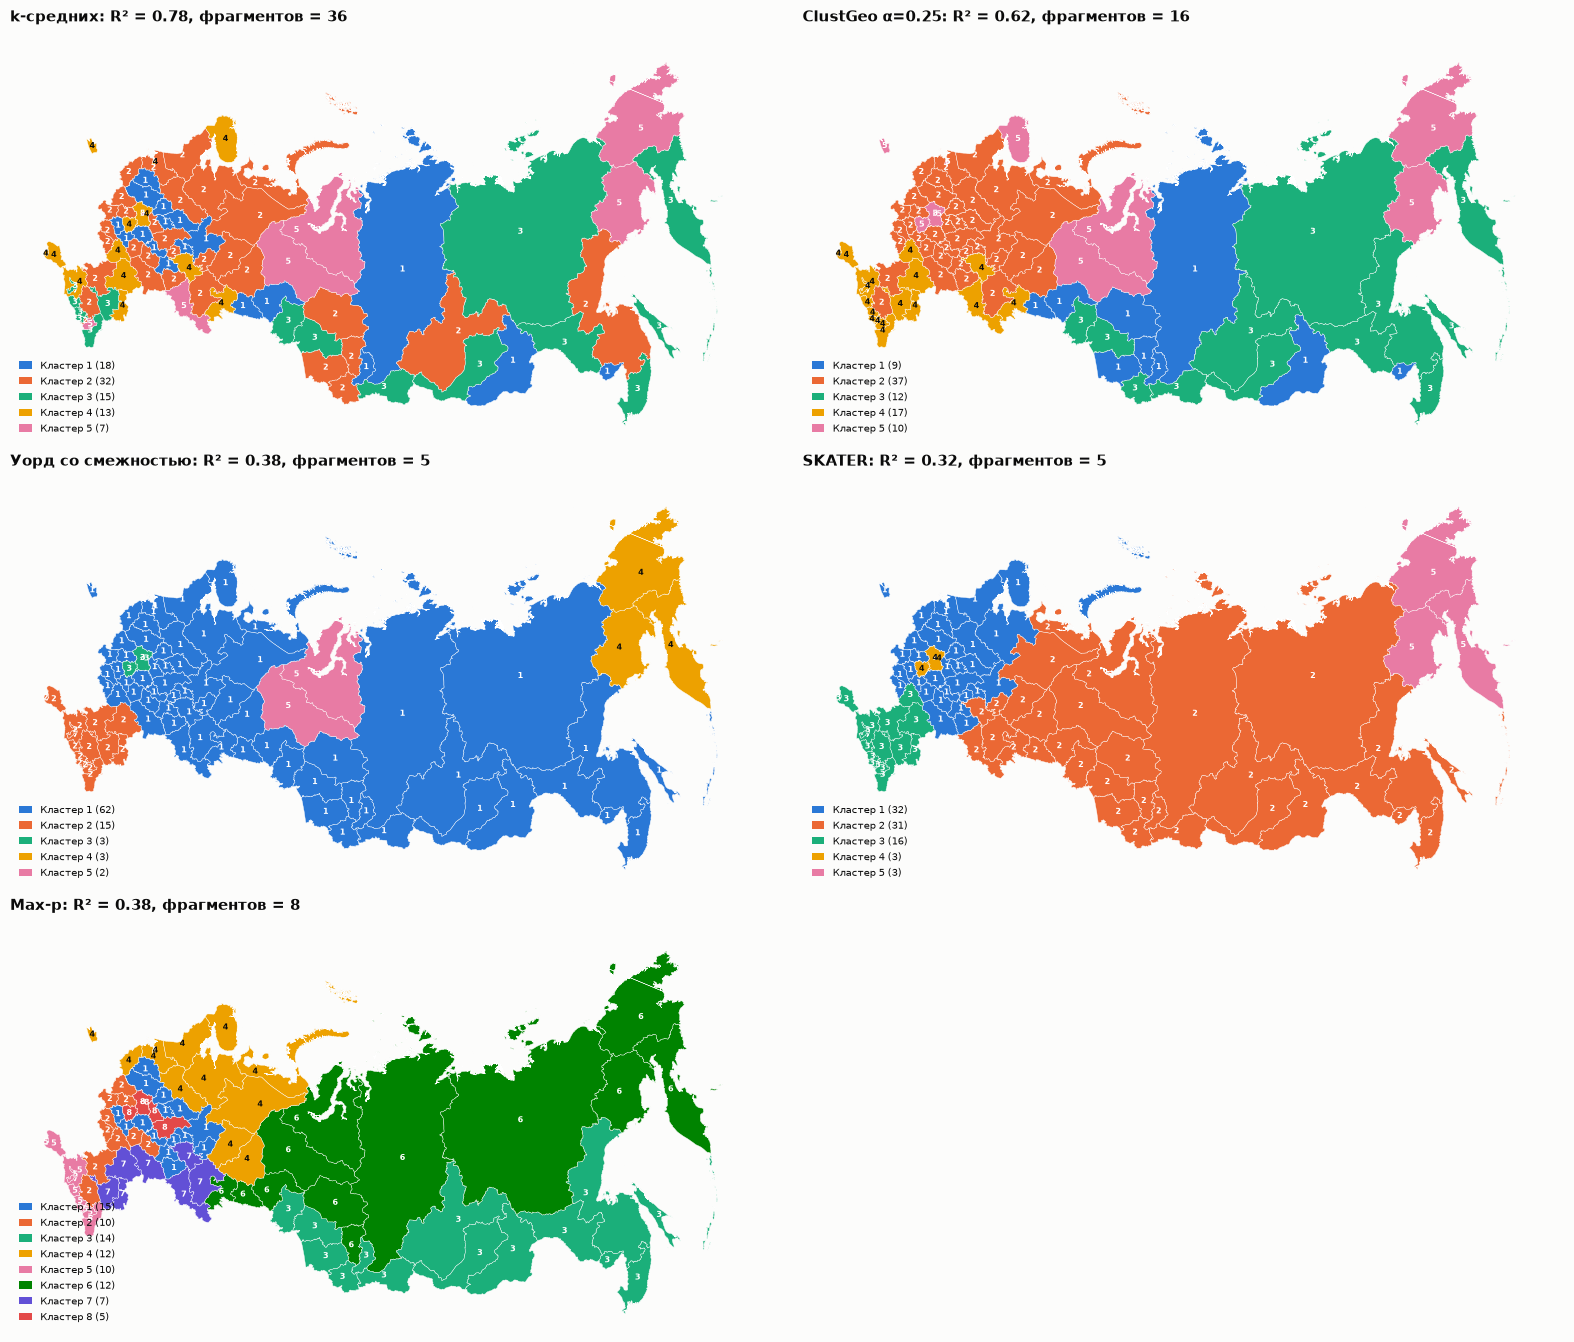

In [16]:
fig, axes = plt.subplots(3, 2, figsize=(16, 13.5))
for ax, (name, lab) in zip(axes.ravel(), labels.items()):
    r = metrics.loc[name]
    cluster_map(ax, gdf, lab, title=f"{name}: R² = {r.R2:.2f}, фрагментов = {int(r['фрагменты'])}")
axes.ravel()[-1].set_axis_off()
plt.tight_layout(); plt.savefig(MAPS / "03_all_partitions.png", dpi=150, bbox_inches="tight"); plt.show()

In [17]:
out = gdf[["okato", "name"]].copy()
for name, lab in labels.items():
    out[name] = lab
out.to_csv(RESULTS / "03_labels.csv", index=False, encoding="utf-8")